# Libraries Import

In [2]:
import sqlite3
import pandas as pd
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem import AllChem
import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import display

import random

import warnings
warnings.filterwarnings('ignore')

In [3]:
#estrazione dati da ChEMBL e creazione dataset ridotto 15000 righe

"""
    connessione = sqlite3.connect('data/chembl_36.db') 

    query = \"""
        SELECT 
            md.chembl_id AS molecule_id,       
            td.chembl_id AS target_id,         
            cs.canonical_smiles AS smiles, 
            act.standard_type AS measure_type,  
            act.standard_units AS measure_unit,
            act.standard_value AS affinity, 
            ts.sequence AS protein_sequence
        FROM activities act
        JOIN assays a ON act.assay_id = a.assay_id
        JOIN target_dictionary td ON a.tid = td.tid
        JOIN target_components tc ON td.tid = tc.tid
        JOIN component_sequences ts ON tc.component_id = ts.component_id
        JOIN compound_structures cs ON act.molregno = cs.molregno
        JOIN molecule_dictionary md ON act.molregno = md.molregno 
        WHERE act.standard_type IN ('IC50', 'Ki', 'Kd') 
        AND act.standard_value IS NOT NULL
        AND cs.canonical_smiles IS NOT NULL
        LIMIT 15000;
    \"""

    df_mini = pd.read_sql_query(query, connessione)
    connessione.close()

    df_mini.to_csv('mini_dataset_chembl.csv', index=False)
    print("Fatto! Ho creato 'mini_dataset_chembl.csv'.")
    df_mini.head() # Così vedi subito se ha funzionato!

"""

'\n    connessione = sqlite3.connect(\'data/chembl_36.db\') \n\n    query = """\n        SELECT \n            md.chembl_id AS molecule_id,       \n            td.chembl_id AS target_id,         \n            cs.canonical_smiles AS smiles, \n            act.standard_type AS measure_type,  \n            act.standard_units AS measure_unit,\n            act.standard_value AS affinity, \n            ts.sequence AS protein_sequence\n        FROM activities act\n        JOIN assays a ON act.assay_id = a.assay_id\n        JOIN target_dictionary td ON a.tid = td.tid\n        JOIN target_components tc ON td.tid = tc.tid\n        JOIN component_sequences ts ON tc.component_id = ts.component_id\n        JOIN compound_structures cs ON act.molregno = cs.molregno\n        JOIN molecule_dictionary md ON act.molregno = md.molregno \n        WHERE act.standard_type IN (\'IC50\', \'Ki\', \'Kd\') \n        AND act.standard_value IS NOT NULL\n        AND cs.canonical_smiles IS NOT NULL\n        LIMIT 15000

# DATA OVERVIEW

In [4]:
df = pd.read_csv('data/mini_dataset_chembl.csv')
df.head(2)

# Investigating the dataset
print(f"\nDataset shape: {df.shape}")
print(f"Dataset columns: {df.columns.tolist()}")
print(f"\nDataset info: ")
df.info()
print(f"\nDataset sample: \n{df.iloc[0]}")



Dataset shape: (15000, 7)
Dataset columns: ['molecule_id', 'target_id', 'smiles', 'measure_type', 'measure_unit', 'affinity', 'protein_sequence']

Dataset info: 
<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   molecule_id       15000 non-null  str    
 1   target_id         15000 non-null  str    
 2   smiles            15000 non-null  str    
 3   measure_type      15000 non-null  str    
 4   measure_unit      15000 non-null  str    
 5   affinity          15000 non-null  float64
 6   protein_sequence  15000 non-null  str    
dtypes: float64(1), str(6)
memory usage: 820.4 KB

Dataset sample: 
molecule_id                                              CHEMBL113081
target_id                                                  CHEMBL1806
smiles                       c1ccc(-c2nc3c(-c4nc5ccccc5o4)cccc3o2)cc1
measure_type                           

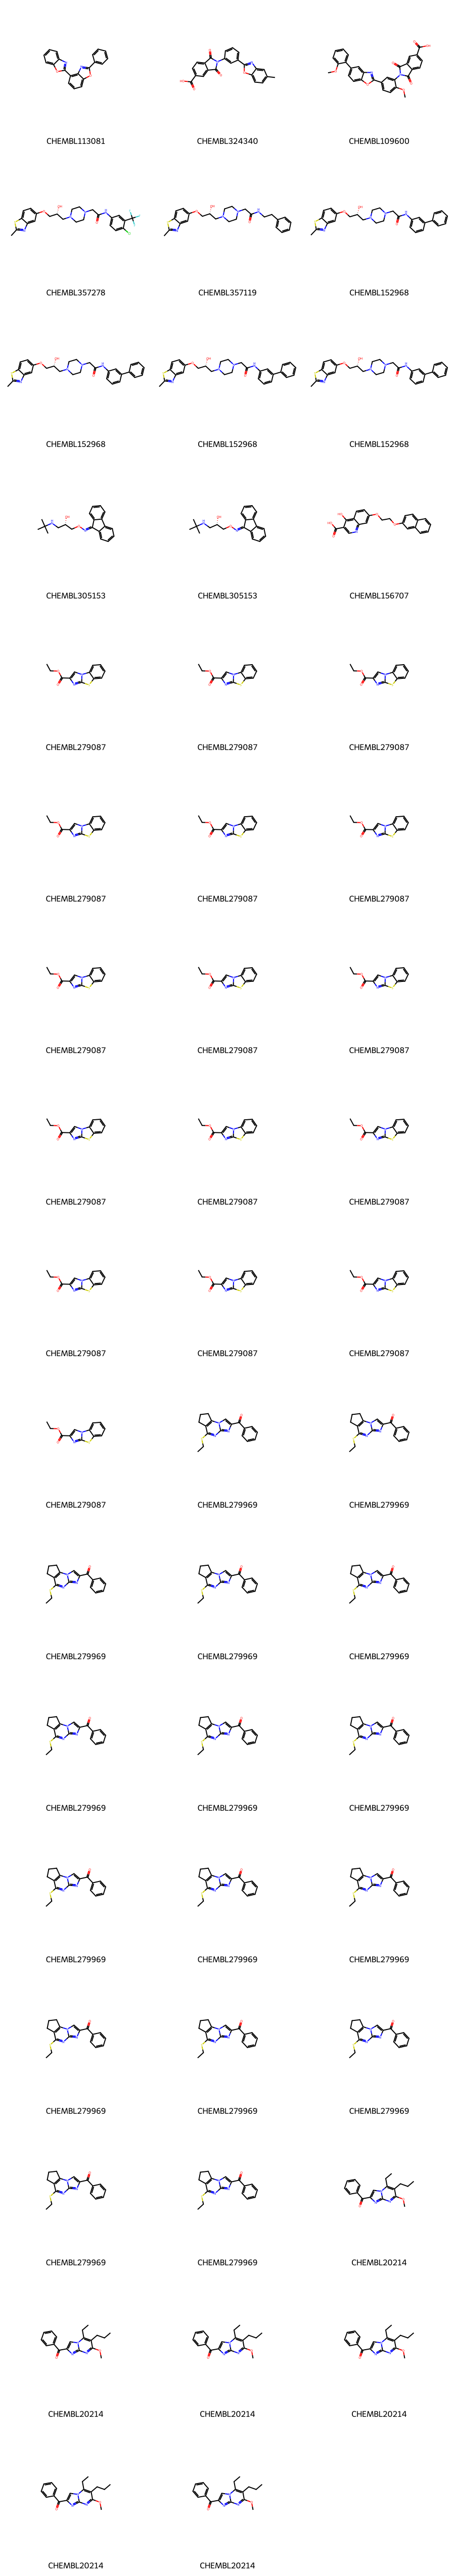

In [5]:
  
#plottare le molecole con RDKit

lista_molecole = []
nomi_molecole = []


for index, row in df.iterrows():
    smiles = row['smiles']
    nome = row['molecule_id']  
    
    molecola = Chem.MolFromSmiles(smiles)
    

    if molecola is not None:
        lista_molecole.append(molecola)
        nomi_molecole.append(nome)

if len(lista_molecole) > 0:
    immagine = Draw.MolsToGridImage(
        lista_molecole, 
        molsPerRow=3,           
        subImgSize=(300, 300),  
        legends=nomi_molecole   
    )
    
display(immagine)  
   

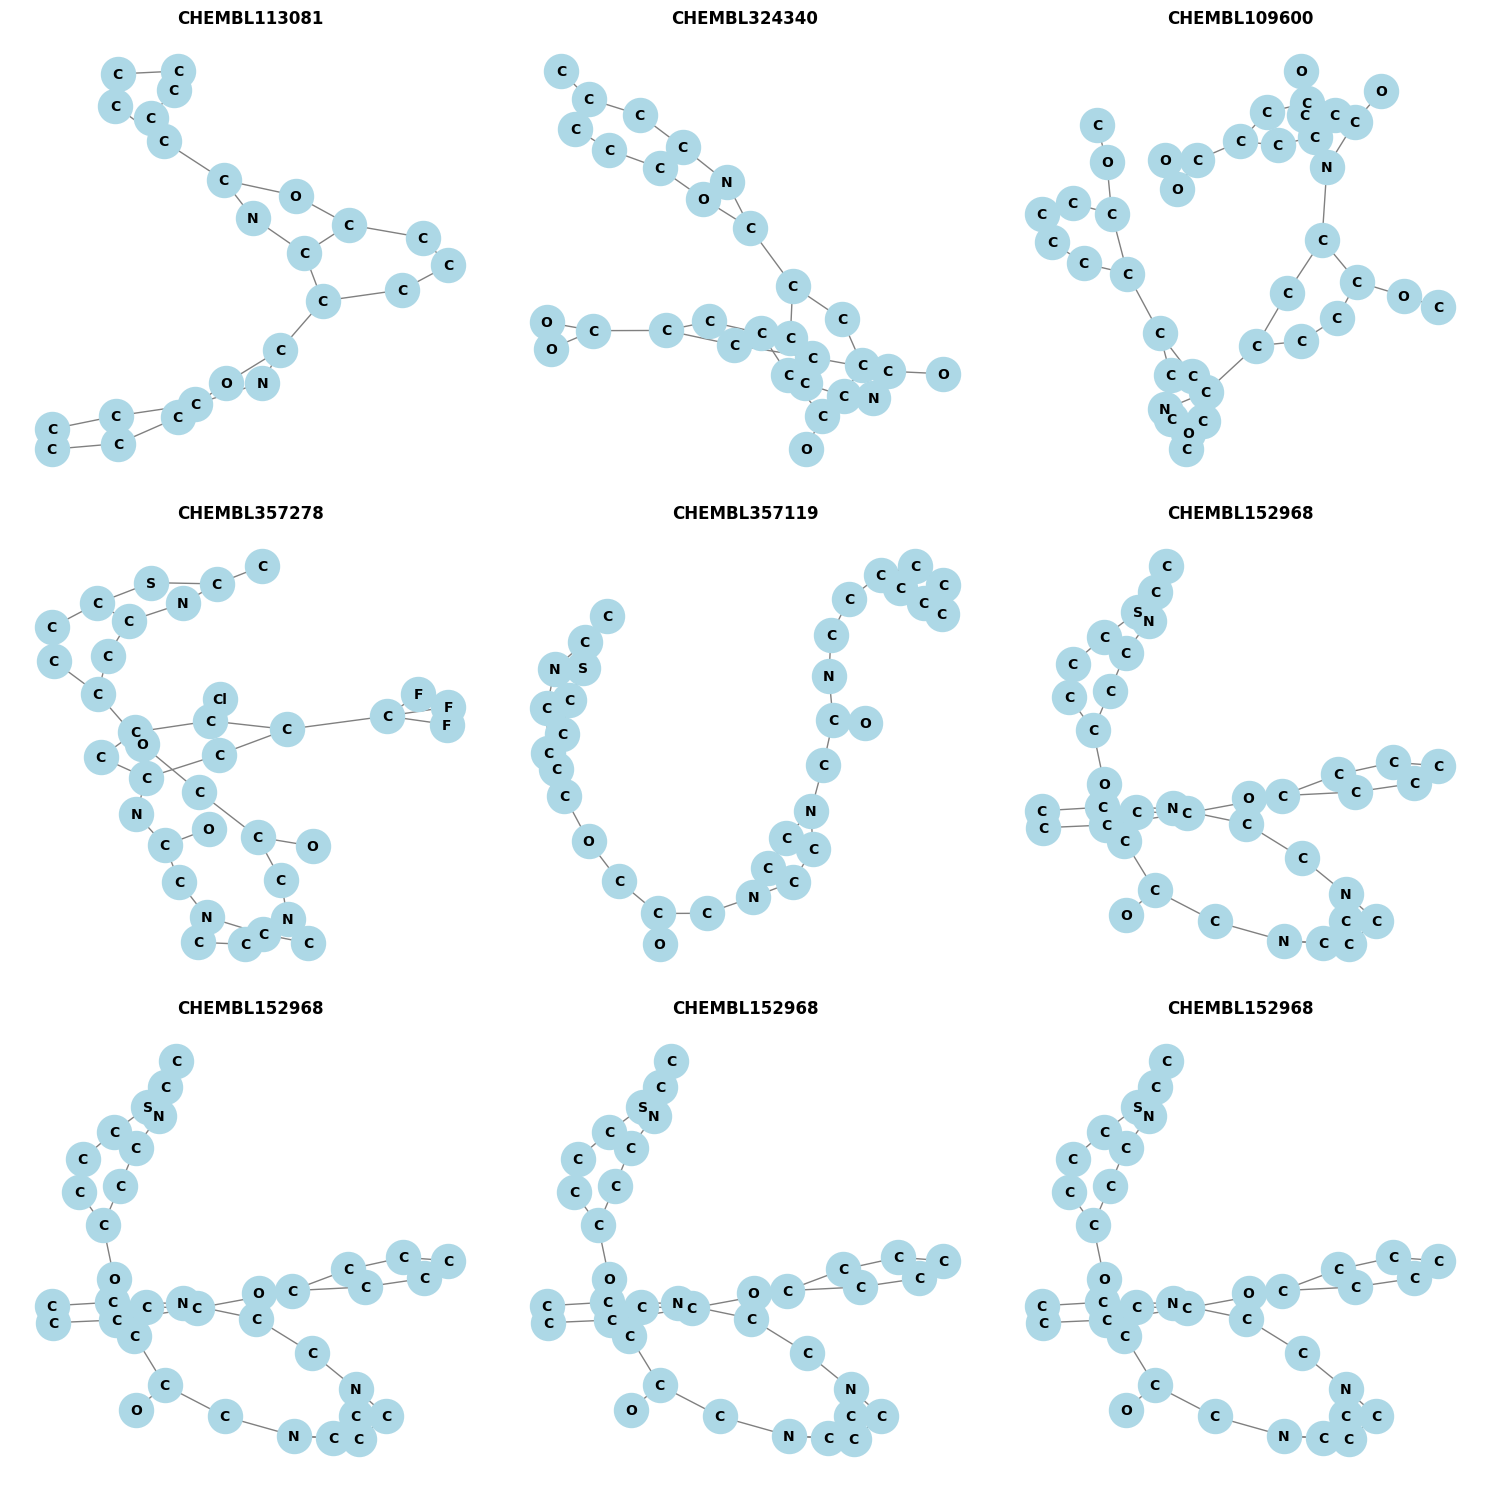

In [6]:
#creiamo e mostriamo i grafi delle molecole con NetworkX e Matplotlib
lista_molecole = []
nomi_molecole = []


for index, row in df.iterrows():
    smiles = row['smiles']
    nome = row['molecule_id'] 
    
    molecola = Chem.MolFromSmiles(smiles)
    if molecola is not None:
        lista_molecole.append(molecola)
        nomi_molecole.append(nome)

# CREIAMO E MOSTRIAMO I GRAFI SOLO PER UN CAMPIONE
# PRENDIAMO SOLO LE PRIME 9 MOLECOLE 
molecole_da_plottare = lista_molecole[:9]
nomi_da_plottare = nomi_molecole[:9]

if len(molecole_da_plottare) > 0:
    colonne = 3
    righe = (len(molecole_da_plottare) + colonne - 1) // colonne
    
    fig, axes = plt.subplots(righe, colonne, figsize=(15, 5 * righe))
    
    if isinstance(axes, plt.Axes):
        axes = [axes]
    else:
        axes = axes.flatten()
    
    for i, molecola in enumerate(molecole_da_plottare):
        G = nx.Graph()
        etichette_nodi = {}
        
        for atom in molecola.GetAtoms():
            idx = atom.GetIdx()
            simbolo = atom.GetSymbol()
            G.add_node(idx)
            etichette_nodi[idx] = simbolo
            
        for bond in molecola.GetBonds():
            G.add_edge(bond.GetBeginAtomIdx(), bond.GetEndAtomIdx())
            
        ax = axes[i]
        
        # Il calcolo del layout è la parte più lenta!
        posizioni = nx.spring_layout(G, seed=42) 
        
        nx.draw(G, posizioni, ax=ax, with_labels=True, labels=etichette_nodi, 
                node_color='lightblue', node_size=600, font_weight='bold', font_size=10, 
                edge_color='gray')
        
        ax.set_title(nomi_da_plottare[i], fontsize=12, fontweight='bold')
        
    for j in range(i + 1, len(axes)):
        axes[j].axis('off')
        
    plt.tight_layout()
    plt.show()
    
else:
    print("Nessuna molecola valida da mostrare.")


Processamento molecole e calcolo coordinate in corso...

Generazione di 9 grafi ...


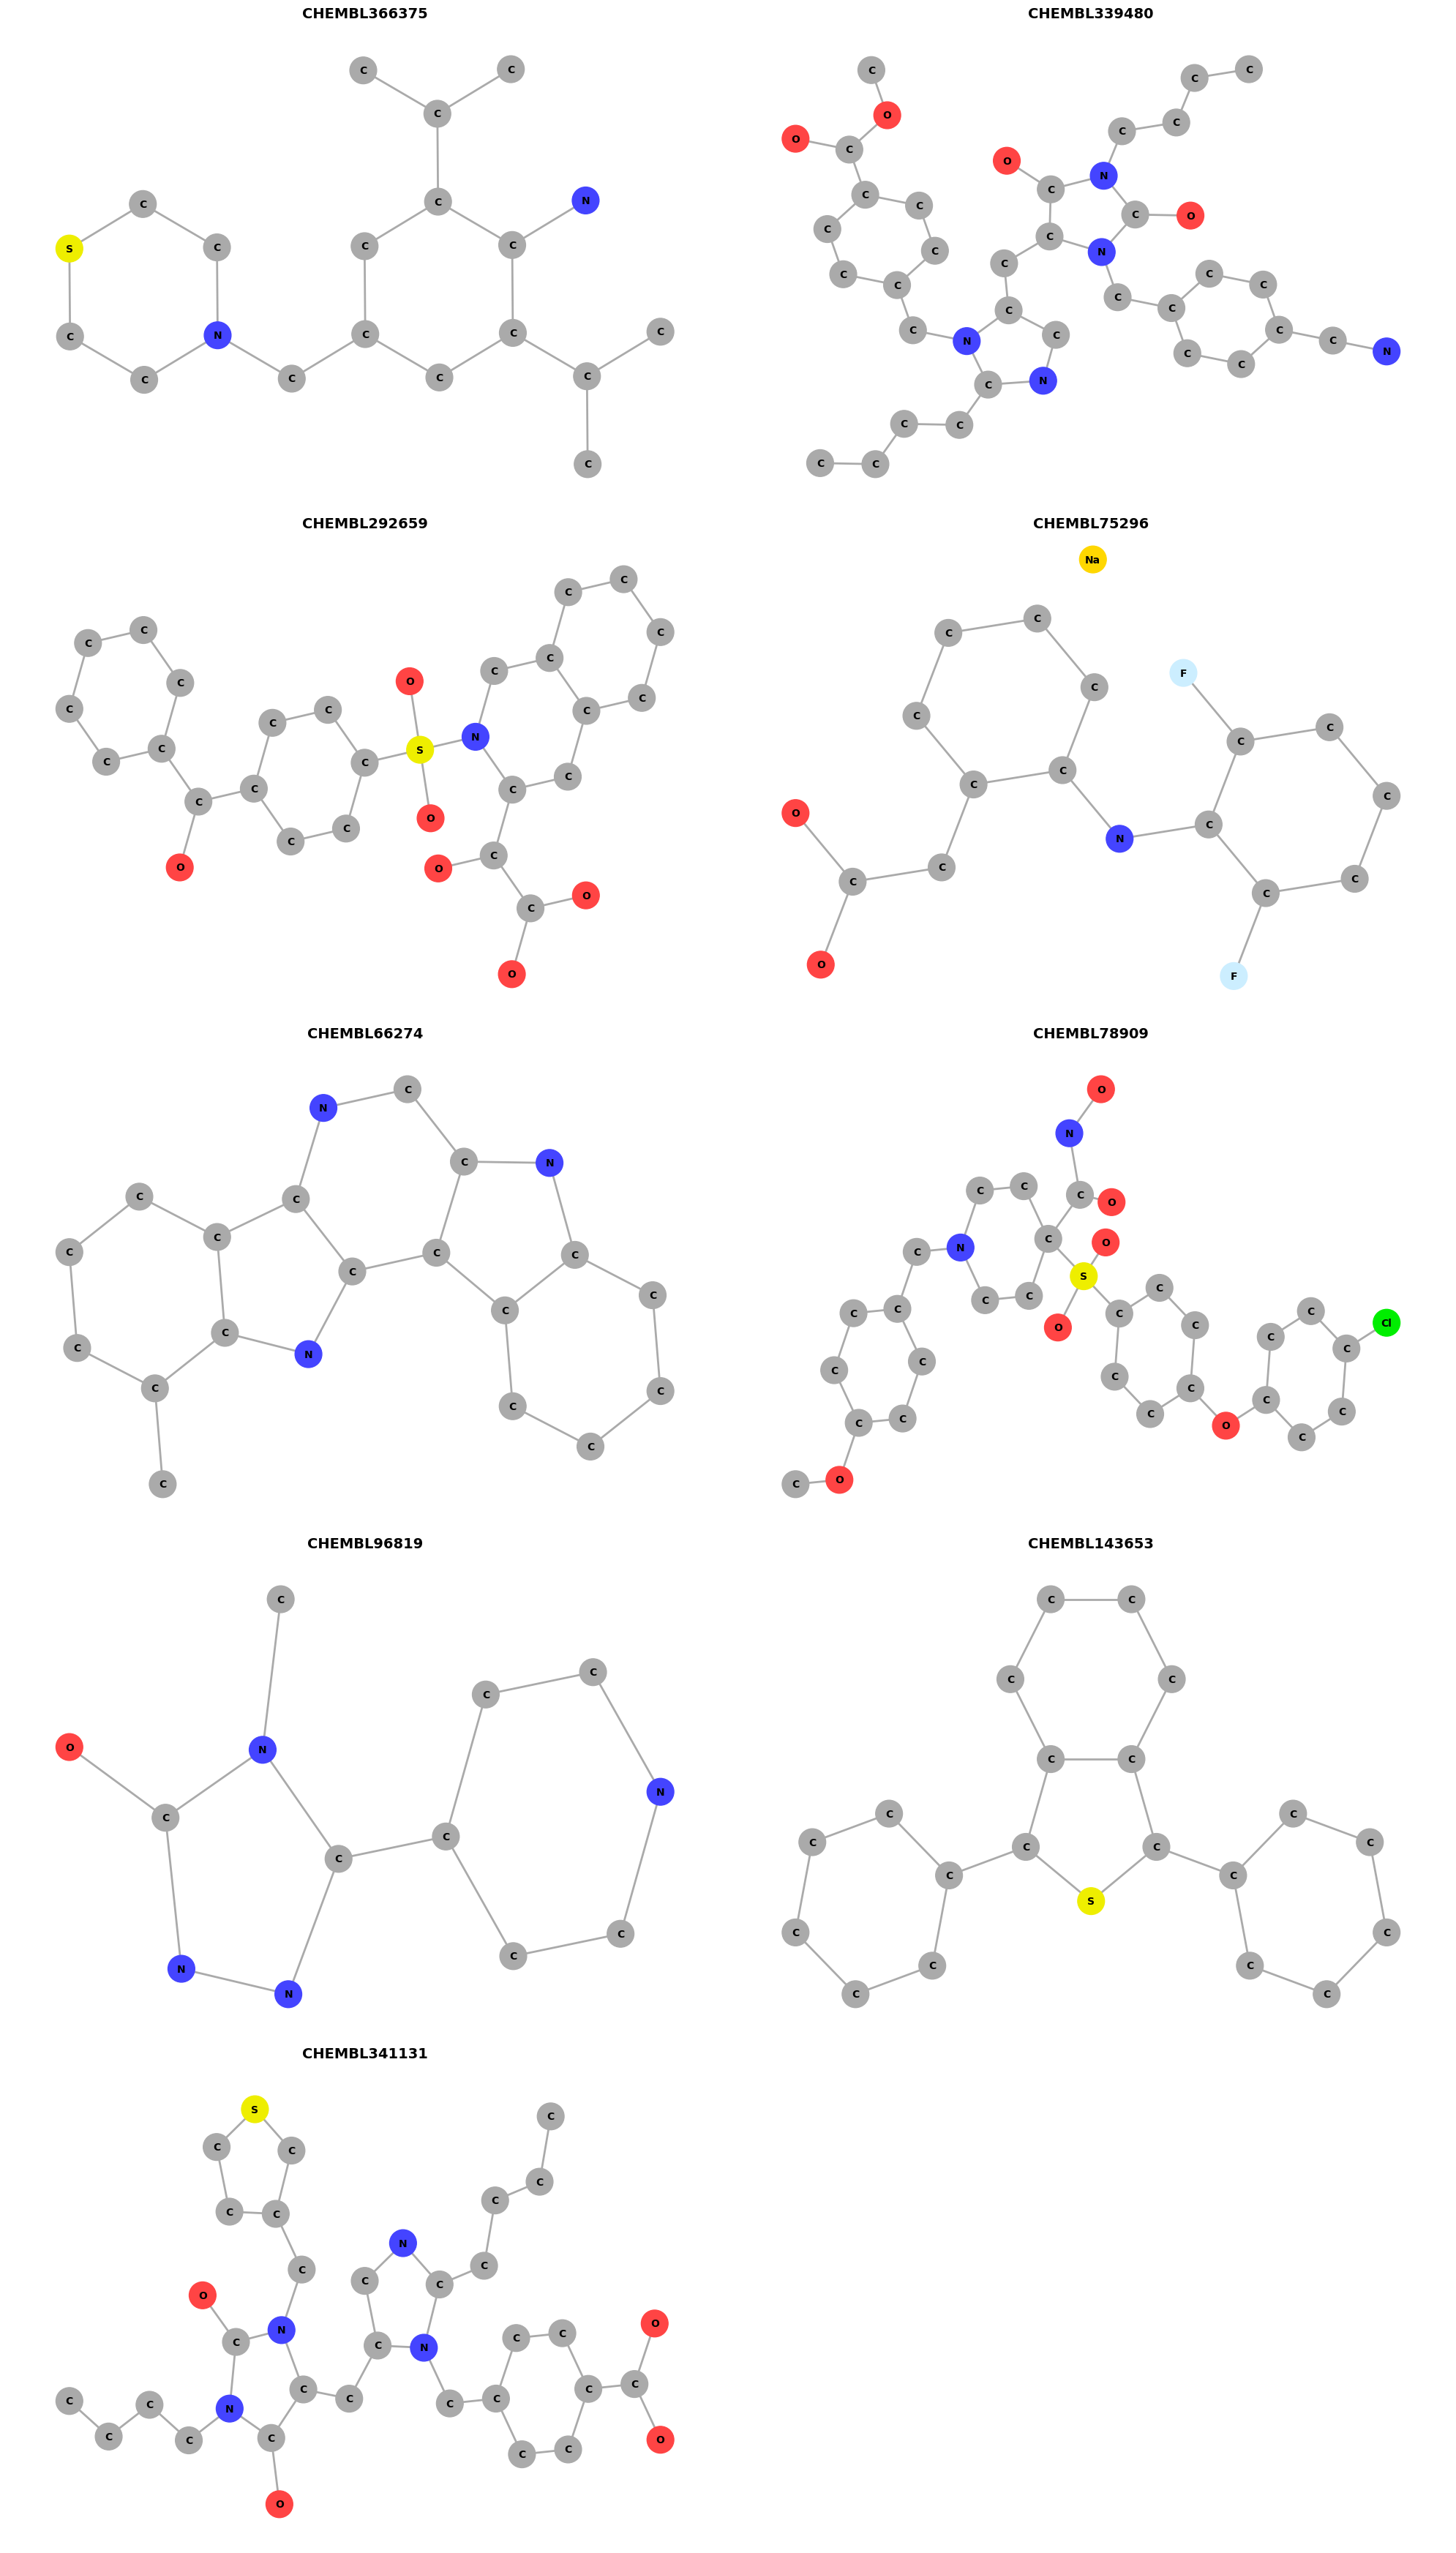

In [7]:


# CODICE COLORE CHIMICO STANDARD (CPK)
# Se un atomo non è in questa lista (es. Iodio, Bromo), verrà usato un colore di default.
color_map_atoms = {
    'C':  '#AAAAAA', # Grigio (per non nascondere le etichette testuali)
    'O':  '#FF4444', # Rosso acceso
    'N':  '#4444FF', # Blu acceso
    'S':  '#EEEE00', # Giallo scuro
    'P':  '#FFA500', # Arancione
    'F':  '#CCEEFF', # Celeste pallido
    'Cl': '#00EE00', # Verde brillante
    'H':  '#FFFFFF'  # Bianco (spesso nascosto)
}
default_color_atom = '#FFD700' # Oro per metalli o elementi rari non in lista


lista_molecole = []
nomi_molecole = []
lista_coordinate = [] 
lista_colori = []    

print("Processamento molecole e calcolo coordinate in corso...")

for index, row in df.iterrows():
    smiles = row['smiles']
    nome = row['molecule_id'] 
    
    mol = Chem.MolFromSmiles(smiles)
    if mol is not None:
    
        # Questo comando calcola una disposizione chimicamente corretta e pulita.
        AllChem.Compute2DCoords(mol)
        
        # Estrarre le coordinate fisse appena calcolate
        conf = mol.GetConformer()
        pos = {}
        atoms_colors = []
        
        for atom in mol.GetAtoms():
            idx = atom.GetIdx()
            
            coordinates = conf.GetAtomPosition(idx)
            pos[idx] = (coordinates.x, coordinates.y)
            
            # Assegnazione colore in base al simbolo chimico
            simbolo = atom.GetSymbol()
            colore = color_map_atoms.get(simbolo, default_color_atom)
            atoms_colors.append(colore)
            
        # Memorizziamo tutto
        lista_molecole.append(mol)
        nomi_molecole.append(nome)
        lista_coordinate.append(pos)
        lista_colori.append(atoms_colors)

# CREIAMO E MOSTRIAMO I GRAFI
# Prendiamo un campione di 9 molecole
sample_size = 9
# Assicuriamoci di non prendere più molecole di quante ne abbiamo
num_to_plot = min(sample_size, len(lista_molecole))

# Selezioniamo casualmente le molecole da plottare
indici = list(range(len(lista_molecole)))
random.shuffle(indici)
indici = indici[:num_to_plot]

molecole_da_plottare   = [lista_molecole[i] for i in indici]
nomi_da_plottare       = [nomi_molecole[i]   for i in indici]
coords_da_plottare     = [lista_coordinate[i] for i in indici]
colori_da_plottare     = [lista_colori[i] for i in indici]

if num_to_plot > 0:
    colonne = 2
    righe = (num_to_plot + colonne - 1) // colonne
    
    # Aumentiamo la dimensione per vederle meglio
    fig, axes = plt.subplots(righe, colonne, figsize=(20, 7 * righe)) 
    
    # Gestione automatica assi se num_to_plot è 1
    if num_to_plot == 1:
        axes = [axes]
    else:
        axes = axes.flatten()
    
    print(f"\nGenerazione di {num_to_plot} grafi ...")
    
    for i, molecola in enumerate(molecole_da_plottare):
        G = nx.Graph()
        etichette_nodi = {}
        
        for atom in molecola.GetAtoms():
            idx = atom.GetIdx()
            simbolo = atom.GetSymbol()
            G.add_node(idx)
            etichette_nodi[idx] = simbolo
            
        for bond in molecola.GetBonds():
            G.add_edge(bond.GetBeginAtomIdx(), bond.GetEndAtomIdx())
            
        ax = axes[i]
        
        posizioni_fisse = coords_da_plottare[i]
        colori_atomi = colori_da_plottare[i]
        
        # Disegniamo usando le posizioni fisse
        nx.draw(G, posizioni_fisse, ax=ax, with_labels=True, labels=etichette_nodi, 
                node_color=colori_atomi,    
                node_size=700,            
                font_weight='bold', font_size=10, 
                edge_color='#AAAAAA',        
                width=2)                    
        
        ax.set_title(nomi_da_plottare[i], fontsize=14, fontweight='bold', pad=10)
        
        # Pulizia: rimuove il bordo del box attorno al grafo
        ax.axis('off')
        
    # Nascondiamo gli assi vuoti se num_to_plot < righe*colonne
    for j in range(i + 1, len(axes)):
        axes[j].axis('off')
        
    plt.tight_layout()
    plt.show()
    
else:
    print("Nessuna molecola valida da mostrare.")

In [8]:
import ligand

ligand = ligand.Ligand(smile=df.iloc[2]['smiles'])
ligand.visualize_py3Dmol()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.